# Práctica 5. Puertas cuánticas de un qubit con Qiskit

## Información general

**Asignatura:** Computación cuántica  
**Sesión:** 5  
**Título:** Puertas cuánticas de un qubit   
**Modalidad:** Individual  
**Entorno recomendado:** Jupyter Notebook  
**Bibliotecas:** NumPy, Matplotlib, Qiskit y Qiskit Aer

## Objetivos

En esta práctica vas a trabajar con puertas cuánticas de un qubit desde dos puntos de vista:

- Como matrices aplicadas a vectores de estado.
- Como operaciones dentro de circuitos de Qiskit.

Al finalizar la práctica deberás ser capaz de:

- Definir puertas cuánticas como matrices unitarias.
- Aplicar puertas a estados de un qubit usando NumPy.
- Reproducir las mismas operaciones con Qiskit.
- Obtener el vector de estado resultante con `Statevector`.
- Calcular probabilidades de medida.
- Distinguir puertas que modifican probabilidades de puertas que modifican fase.
- Analizar el efecto del orden de aplicación de las puertas.
- Simular medidas y comparar probabilidades teóricas con conteos experimentales.

## Entrega

Entrega este notebook completado con:

- Código ejecutado.
- Resultados visibles.
- Tablas completadas cuando se soliciten.
- Gráficas generadas.
- Respuestas razonadas en las celdas indicadas.
- Conclusión final.

## 1. Preparación del entorno

Ejecuta la siguiente celda para importar las bibliotecas necesarias.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

SEMILLA = 42

## 2. Parte A. Puertas como matrices

### Ejercicio 1. Estados de la base computacional

Define con NumPy los estados:

$$
|0\rangle =
\begin{pmatrix}
1 \\
0
\end{pmatrix}
$$

$$
|1\rangle =
\begin{pmatrix}
0 \\
1
\end{pmatrix}
$$

Utiliza explícitamente `dtype=complex`.

In [2]:
ket_0 = np.array([1, 0], dtype=complex)
ket_1 = np.array([0, 1], dtype=complex)

print("|0> =", ket_0)
print("|1> =", ket_1)

print("Norma de |0>:", np.linalg.norm(ket_0))
print("Norma de |1>:", np.linalg.norm(ket_1))

|0> = [1.+0.j 0.+0.j]
|1> = [0.+0.j 1.+0.j]
Norma de |0>: 1.0
Norma de |1>: 1.0


**Responde:**

1. ¿Qué representa cada componente del vector?
    - La amplitud de $\ket0$ y $\ket1$
2. ¿Por qué la norma debe ser 1?
    - Porque las probabilidades tienen que sumar 1.
3. ¿Por qué usamos `dtype=complex`?
    - Porque las amplitudes son numeros complejos.

### Ejercicio 2. Definición de puertas básicas

Define con NumPy las matrices de las siguientes puertas:

$$
I =
\begin{pmatrix}
1 & 0 \\
0 & 1
\end{pmatrix}
$$

$$
X =
\begin{pmatrix}
0 & 1 \\
1 & 0
\end{pmatrix}
$$

$$
Y =
\begin{pmatrix}
0 & -i \\
i & 0
\end{pmatrix}
$$

$$
Z =
\begin{pmatrix}
1 & 0 \\
0 & -1
\end{pmatrix}
$$

$$
H =
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1 & 1 \\
1 & -1
\end{pmatrix}
$$

In [3]:
I = np.array([[1, 0], [0, 1]], dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)

puertas_basicas = {
    "I": I,
    "X": X,
    "Y": Y,
    "Z": Z,
    "H": H,
}

for nombre, puerta in puertas_basicas.items():
    print(f"{nombre} =")
    print(puerta)
    print()

I =
[[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]

X =
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]

Y =
[[ 0.+0.j -0.-1.j]
 [ 0.+1.j  0.+0.j]]

Z =
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]

H =
[[ 0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j]]



**Responde:**

1. ¿Qué dimensión tiene cada matriz?
    - 2x2
2. ¿Por qué una puerta de un qubit se representa con una matriz 2 x 2?
    - Porque actua sobre un vector de dos componentes y tiene que devolver otro de dos componentes.
3. ¿Qué diferencia observas entre las puertas X, Y y Z?
    - $X$ intercambia $\ket0$ y $\ket1$. $Z$ deja igual $\ket0$ y cambia el signo de $\ket1$. $Y$ hace las dos cosas a la vez con un factor $i$.

### Ejercicio 3. Comprobación de unitariedad

Implementa una función que compruebe si una matriz es unitaria:

$$
U^\dagger U = I
$$

Recuerda que $U^\dagger$ es la traspuesta conjugada de U.

In [4]:
def es_unitaria(U, tolerancia=1e-10):
    '''
    Comprueba si una matriz es unitaria.
    '''
    # TODO: convierte U a array complejo
    U = np.array(U, dtype=complex)

    # TODO: comprueba que sea cuadrada
    if U.ndim != 2 or U.shape[0] != U.shape[1]:
            return False

    # TODO: calcula la matriz identidad del mismo tamaño
    identidad = np.eye(U.shape[0], dtype=complex)

    # TODO: comprueba U^dagger U = I
    return np.allclose(U.conj().T @ U, identidad, atol=tolerancia)

In [5]:
for nombre, puerta in puertas_basicas.items():
    print(nombre, es_unitaria(puerta))

I True
X True
Y True
Z True
H True


Completa la tabla:

| Puerta | ¿Es unitaria? |
|---|---:|
| I | Sí |
| X | Sí |
| Y | Sí |
| Z | Sí |
| H | Sí |

**Responde:**

1. ¿Son unitarias todas las puertas anteriores?
    - Si.
2. ¿Qué propiedad del estado garantiza la unitariedad?
    - Conserva la norma del estado, siguen siendo 1 la suma de las probabilidades.
3. ¿Por qué una puerta cuántica debe ser reversible?
    - Para que no se pierda información.

## 3. Parte B. Aplicación de puertas con NumPy

### Ejercicio 4. Función para calcular probabilidades

Implementa una función que devuelva las probabilidades de medir 0 y 1 en la base computacional.

In [6]:
def probabilidades(estado):
    '''
    Devuelve las probabilidades de medir 0 y 1.
    '''
    # convierte el estado a array complejo
    estado = np.array(estado, dtype=complex)

    # módulo al cuadrado de cada amplitud
    probs = np.abs(estado) ** 2

    return {
        0: float(probs[0]),
        1: float(probs[1]),
    }

### Ejercicio 5. Aplicar puertas a $|0\rangle$

Aplica las puertas I, X, Y, Z y H al estado $|0\rangle$.

In [7]:
resultados_ket0 = {}

for nombre, puerta in puertas_basicas.items():
    estado_final = puerta @ ket_0
    resultados_ket0[nombre] = estado_final

    print(f"{nombre}|0> = {estado_final}")
    print("Probabilidades:", probabilidades(estado_final))
    print()

I|0> = [1.+0.j 0.+0.j]
Probabilidades: {0: 1.0, 1: 0.0}

X|0> = [0.+0.j 1.+0.j]
Probabilidades: {0: 0.0, 1: 1.0}

Y|0> = [0.+0.j 0.+1.j]
Probabilidades: {0: 0.0, 1: 1.0}

Z|0> = [1.+0.j 0.+0.j]
Probabilidades: {0: 1.0, 1: 0.0}

H|0> = [0.70710678+0.j 0.70710678+0.j]
Probabilidades: {0: 0.4999999999999999, 1: 0.4999999999999999}



Completa la tabla:

| Puerta | Estado resultante | Probabilidad de 0 | Probabilidad de 1 |
|---|---|---:|---:|
| I | $\|0\rangle$ | 1 | 0 |
| X | $\|1\rangle$ | 0 | 1 |
| Y | $i\|1\rangle$ | 0 | 1 |
| Z | $\|0\rangle$ | 1 | 0 |
| H | $(\|0\rangle+\|1\rangle)/\sqrt{2}$ | 0,5 | 0,5 |

**Responde:**

1. ¿Qué puertas cambian las probabilidades al aplicarse sobre $|0\rangle$?
    - $X,Y,H$
2. ¿Qué puertas no cambian las probabilidades?
    - $I,Z$
3. ¿Qué diferencia hay entre $X|0\rangle$ e $Y|0\rangle$?
    - Solo se diferencian en el factor $i$.
4. ¿Se puede distinguir esa diferencia midiendo directamente en la base computacional?
    - No. Porque con una medida directa ambos dan 1 con probabilidad 1. La $i$ es una fase global.

### Ejercicio 6. Aplicar puertas a $|1\rangle$

Repite el ejercicio anterior aplicando las mismas puertas a $|1\rangle$.

In [8]:
resultados_ket1 = {}

for nombre, puerta in puertas_basicas.items():
    estado_final = puerta @ ket_1
    resultados_ket1[nombre] = estado_final

    print(f"{nombre}|1> = {estado_final}")
    print("Probabilidades:", probabilidades(estado_final))
    print()

I|1> = [0.+0.j 1.+0.j]
Probabilidades: {0: 0.0, 1: 1.0}

X|1> = [1.+0.j 0.+0.j]
Probabilidades: {0: 1.0, 1: 0.0}

Y|1> = [0.-1.j 0.+0.j]
Probabilidades: {0: 1.0, 1: 0.0}

Z|1> = [ 0.+0.j -1.+0.j]
Probabilidades: {0: 0.0, 1: 1.0}

H|1> = [ 0.70710678+0.j -0.70710678+0.j]
Probabilidades: {0: 0.4999999999999999, 1: 0.4999999999999999}



Completa la tabla:

| Puerta | Estado resultante | Probabilidad de 0 | Probabilidad de 1 |
|---|---|---:|---:|
| I | $\|1\rangle$ | 0 | 1 |
| X | $\|0\rangle$ | 1 | 0 |
| Y | $-i\|0\rangle$ | 1 | 0 |
| Z | $-\|1\rangle$ | 0 | 1 |
| H | $(\|0\rangle-\|1\rangle)/\sqrt{2}$ | 0,5 | 0,5 |

**Responde:**

1. ¿Qué resultado produce $X|1\rangle$?
    - $\ket0$
2. ¿Qué resultado produce $Z|1\rangle$?
    - -$\ket1$
3. ¿Son físicamente distinguibles $|1\rangle$ y $-|1\rangle$ mediante una medida directa?
    - No, el signo es una fase global.
4. ¿Qué estado produce $H|1\rangle$?
    - $(\ket0-\ket1)/\sqrt2$

Respuesta:

### Ejercicio 7. Estados $|+\rangle$ y $|-\rangle$

Define los estados:

$$
|+\rangle =
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

$$
|-\rangle =
\frac{|0\rangle - |1\rangle}{\sqrt{2}}
$$

In [9]:
ket_plus = (ket_0 + ket_1) / np.sqrt(2)
ket_minus = (ket_0 - ket_1) / np.sqrt(2)

print("|+> =", ket_plus)
print("|-> =", ket_minus)

print("Norma |+>:", np.linalg.norm(ket_plus))
print("Norma |->:", np.linalg.norm(ket_minus))

print("Probabilidades |+>:", probabilidades(ket_plus))
print("Probabilidades |->:", probabilidades(ket_minus))

|+> = [0.70710678+0.j 0.70710678+0.j]
|-> = [ 0.70710678+0.j -0.70710678+0.j]
Norma |+>: 0.9999999999999999
Norma |->: 0.9999999999999999
Probabilidades |+>: {0: 0.4999999999999999, 1: 0.4999999999999999}
Probabilidades |->: {0: 0.4999999999999999, 1: 0.4999999999999999}


**Responde:**

1. ¿Tienen las mismas probabilidades en la base computacional?
    - Sí, las dos son 0,5 para 0 y para 1.
2. ¿Son el mismo estado?
    - No.
3. ¿Qué diferencia hay entre ellos?
    - El signo de la amplitud de $\ket1$, la fase relativa.
4. ¿Qué concepto aparece aquí?
    - La fase relativa.
    

## 4. Parte C. Las mismas puertas con Qiskit

### Ejercicio 8. Puerta X en Qiskit

Crea un circuito de un qubit que aplique una puerta X, dibújalo y obtén su vector de estado.

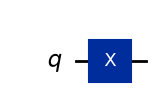

<IPython.core.display.Latex object>

{np.str_('1'): np.float64(1.0)}


In [10]:
qc = QuantumCircuit(1)
qc.x(0)

display(qc.draw("mpl"))

estado = Statevector.from_instruction(qc)
display(estado.draw("latex"))
print(estado.probabilities_dict())

**Responde:**

1. ¿Cuál es el estado inicial por defecto en Qiskit?
    - $\ket0$
2. ¿Qué estado se obtiene después de aplicar \(X\)?
    - $\ket1$
3. ¿Coincide con el cálculo hecho con NumPy?
    - Si.

### Ejercicio 9. Función auxiliar para analizar circuitos

Completa la función `analizar_circuito`.

In [15]:
def analizar_circuito(qc):
    '''
    Dibuja un circuito, muestra su Statevector y devuelve sus probabilidades.
    '''
    # obtiene el vector de estado
    estado = Statevector.from_instruction(qc)

    display(qc.draw("mpl"))
    display(estado.draw("latex"))

    probs = estado.probabilities_dict()
    print(probs)

    return estado, probs

### Ejercicio 10. Puertas I, X, Y, Z y H en Qiskit

Crea un circuito independiente para cada una de las puertas:

- `id`
- `x`
- `y`
- `z`
- `h`

Todas deben aplicarse sobre el estado inicial $|0\rangle$.

Puerta: I


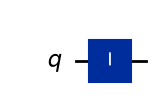

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(1.0)}

Puerta: X


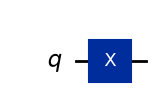

<IPython.core.display.Latex object>

{np.str_('1'): np.float64(1.0)}

Puerta: Y


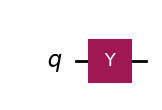

<IPython.core.display.Latex object>

{np.str_('1'): np.float64(1.0)}

Puerta: Z


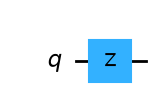

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(1.0)}

Puerta: H


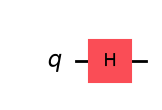

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}



In [16]:
circuitos_qiskit = {}

qc_id = QuantumCircuit(1)
qc_id.id(0)
circuitos_qiskit["I"] = qc_id

qc_x = QuantumCircuit(1)
qc_x.x(0)
circuitos_qiskit["X"] = qc_x

qc_y = QuantumCircuit(1)
qc_y.y(0)
circuitos_qiskit["Y"] = qc_y

qc_z = QuantumCircuit(1)
qc_z.z(0)
circuitos_qiskit["Z"] = qc_z

qc_h = QuantumCircuit(1)
qc_h.h(0)
circuitos_qiskit["H"] = qc_h

for nombre, circuito in circuitos_qiskit.items():
    print("Puerta:", nombre)
    analizar_circuito(circuito)
    print()

**Responde:**

1. ¿Qué puertas producen cambios visibles en las probabilidades?
    - $X,Y,H$
2. ¿Qué puertas producen cambios de fase?
    - $Z$ cambia la fase relativa e $Y$ añade una fase $i$ al estado final.
3. ¿Qué información muestra `Statevector` que no aparece en un histograma?
    - Las amplitudes complejas, las fases. Un histograma solo muestra probabilidades

## 5. Parte D. Puertas de fase

### Ejercicio 11. Puertas S y T con NumPy

Define con NumPy las puertas:

$$
S =
\begin{pmatrix}
1 & 0 \\
0 & i
\end{pmatrix}
$$

$$
T =
\begin{pmatrix}
1 & 0 \\
0 & e^{i\pi/4}
\end{pmatrix}
$$

In [17]:
S = np.array([[1, 0], [0, 1j]], dtype=complex)
T = np.array([[1, 0], [0, np.exp(1j * np.pi / 4)]], dtype=complex)

print("S =")
print(S)
print()
print("T =")
print(T)

print("S unitaria:", es_unitaria(S))
print("T unitaria:", es_unitaria(T))

S =
[[1.+0.j 0.+0.j]
 [0.+0.j 0.+1.j]]

T =
[[1.        +0.j         0.        +0.j        ]
 [0.        +0.j         0.70710678+0.70710678j]]
S unitaria: True
T unitaria: True


In [18]:
estados_para_fase = {
    "|0>": ket_0,
    "|1>": ket_1,
    "|+>": ket_plus,
}

puertas_fase = {
    "S": S,
    "T": T,
}

for nombre_puerta, puerta in puertas_fase.items():
    for nombre_estado, estado_inicial in estados_para_fase.items():
        estado_final = puerta @ estado_inicial
        print(f"{nombre_puerta} sobre {nombre_estado}: {estado_final}")
        print("Probabilidades:", probabilidades(estado_final))
        print()

S sobre |0>: [1.+0.j 0.+0.j]
Probabilidades: {0: 1.0, 1: 0.0}

S sobre |1>: [0.+0.j 0.+1.j]
Probabilidades: {0: 0.0, 1: 1.0}

S sobre |+>: [0.70710678+0.j         0.        +0.70710678j]
Probabilidades: {0: 0.4999999999999999, 1: 0.4999999999999999}

T sobre |0>: [1.+0.j 0.+0.j]
Probabilidades: {0: 1.0, 1: 0.0}

T sobre |1>: [0.        +0.j         0.70710678+0.70710678j]
Probabilidades: {0: 0.0, 1: 1.0000000000000004}

T sobre |+>: [0.70710678+0.j  0.5       +0.5j]
Probabilidades: {0: 0.4999999999999999, 1: 0.5000000000000001}



Completa la tabla:

| Puerta | Estado inicial | Estado final | Probabilidades |
|---|---|---|---|
| S | $\|0\rangle$ | $\|0\rangle$ | P(0)=1, P(1)=0 |
| S | $\|1\rangle$ | $i\|1\rangle$ | P(0)=0, P(1)=1 |
| S | $\|+\rangle$ | $(\|0\rangle+i\|1\rangle)/\sqrt{2}$ | P(0)=0,5, P(1)=0,5 |
| T | $\|0\rangle$ | $\|0\rangle$ | P(0)=1, P(1)=0 |
| T | $\|1\rangle$ | $e^{i\pi/4}\|1\rangle$ | P(0)=0, P(1)=1 |
| T | $\|+\rangle$ | $(\|0\rangle+e^{i\pi/4}\|1\rangle)/\sqrt{2}$ | P(0)=0,5, P(1)=0,5 |

**Responde:**

1. ¿Cambian las probabilidades al aplicar S o T sobre $|0\rangle$?
    - No, siguen siendo $\ket0$.
2. ¿Cambian las probabilidades al aplicarlas sobre $|1\rangle$?
    - No, solo aparece una fase flobal en $\ket1$ y las probabilidades siguen siendo 0 y 1.
3. ¿Qué cambia realmente?
    - Cambia la fase de la componente $\ket1$. Sobre $\ket+$ cambia la fase relativa.
4. ¿Por qué es importante la fase relativa?
    - Porque determina como interfieren las amplitudes cuando se aplican más puertas.

### Ejercicio 12. Puertas S y T en Qiskit

Reproduce el ejercicio anterior con Qiskit preparando primero $|+\rangle$ y aplicando después `s` o `t`.

Circuito H + S


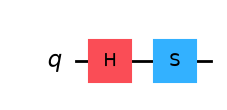

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
Circuito H + T


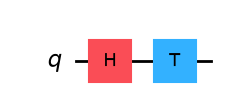

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
S coincide con NumPy: True
T coincide con NumPy: True


In [19]:
qc_s = QuantumCircuit(1)
qc_s.h(0)
qc_s.s(0)

qc_t = QuantumCircuit(1)
qc_t.h(0)
qc_t.t(0)

print("Circuito H + S")
estado_s, probs_s = analizar_circuito(qc_s)

print("Circuito H + T")
estado_t, probs_t = analizar_circuito(qc_t)

print("S coincide con NumPy:", np.allclose(estado_s.data, S @ ket_plus))
print("T coincide con NumPy:", np.allclose(estado_t.data, T @ ket_plus))

**Responde:**

1. ¿Coinciden los resultados con NumPy?
    - Si.
2. ¿Qué diferencia hay entre `s` y `t`?
    - $S$ añade una fase de $\pi/2$ (factor $i$) y $T$ una fase de $\pi/4$ (factor $e^{i\pi/4}$)
3. ¿Puede una puerta cambiar el estado sin cambiar las probabilidades de medida en la base computacional?
    - Si, si la puerta solo cambia la fase el estado es distinto pero las probabilidades son las mismas.

## 6. Parte E. Fase relativa e interferencia

### Ejercicio 13. Comparación entre $|+\rangle$ y $|-\rangle$

Crea dos circuitos.

Circuito A:

```python
qc_a = QuantumCircuit(1)
qc_a.h(0)
```

Circuito B:

```python
qc_b = QuantumCircuit(1)
qc_b.h(0)
qc_b.z(0)
```

Circuito A


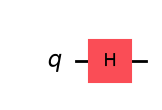

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
Circuito B


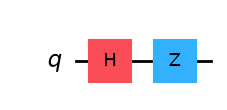

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


In [20]:
qc_a = QuantumCircuit(1)
qc_a.h(0)

qc_b = QuantumCircuit(1)
qc_b.h(0)
qc_b.z(0)

print("Circuito A")
estado_a, probs_a = analizar_circuito(qc_a)

print("Circuito B")
estado_b, probs_b = analizar_circuito(qc_b)

**Responde:**

1. ¿Qué estado prepara el circuito A?
    - $\ket+$
2. ¿Qué estado prepara el circuito B?
    - $\ket-$
3. ¿Tienen las mismas probabilidades?
    - Sí. 0,5 y 0,5.
4. ¿Son el mismo estado?
    - No, son distintos.
5. ¿Qué diferencia hay entre ellos?
    - Distinta fase relativa.

### Ejercicio 14. Convertir fase en probabilidad

Añade una puerta H al final de los dos circuitos anteriores.

Circuito A:

```python
qc_a = QuantumCircuit(1)
qc_a.h(0)
qc_a.h(0)
```

Circuito B:

```python
qc_b = QuantumCircuit(1)
qc_b.h(0)
qc_b.z(0)
qc_b.h(0)
```

Circuito A final


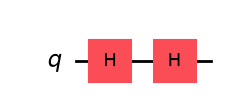

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.9999999999999996)}
Circuito B final


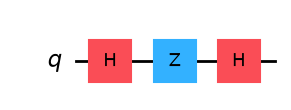

<IPython.core.display.Latex object>

{np.str_('1'): np.float64(0.9999999999999996)}


In [21]:
qc_a_final = QuantumCircuit(1)
qc_a_final.h(0)
qc_a_final.h(0)

qc_b_final = QuantumCircuit(1)
qc_b_final.h(0)
qc_b_final.z(0)
qc_b_final.h(0)

print("Circuito A final")
estado_a_final, probs_a_final = analizar_circuito(qc_a_final)

print("Circuito B final")
estado_b_final, probs_b_final = analizar_circuito(qc_b_final)

Completa la tabla:

| Circuito | Estado antes de la última H | Estado final | P(0) | P(1) |
|---|---|---|---:|---:|
| A | $\|+\rangle$ | $\|0\rangle$ | 1 | 0 |
| B | $\|-\rangle$ | $\|1\rangle$ | 0 | 1 |

**Responde:**

1. ¿Qué resultado produce el circuito A?
    - $\ket0$ con probabilidad 1
2. ¿Qué resultado produce el circuito B?
    -$\ket1$ con probabilidad 1
3. ¿Por qué ahora sí aparece una diferencia en las probabilidades?
    - Porque la última $H$ convierte la diferencia de fase en una diferencia de amplitudes.
4. ¿Qué relación tiene esto con la interferencia cuántica?
    - Es interferencia: en el circuito A las amplitudes de $\ket1$ se cancelan (destructiva) y las de $\ket0$ se suman (constructiva). En el B pasa al revés por el signo que añadió $Z$

## 7. Parte F. Composición y orden de puertas

### Ejercicio 15. Comparación de órdenes

Crea dos circuitos:

Circuito 1:

```python
qc1 = QuantumCircuit(1)
qc1.h(0)
qc1.z(0)
```

Circuito 2:

```python
qc2 = QuantumCircuit(1)
qc2.z(0)
qc2.h(0)
```

Circuito 1: H y después Z


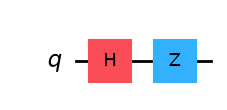

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
Circuito 2: Z y después H


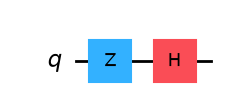

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


In [22]:
qc1 = QuantumCircuit(1)
qc1.h(0)
qc1.z(0)

qc2 = QuantumCircuit(1)
qc2.z(0)
qc2.h(0)

print("Circuito 1: H y después Z")
estado_1, probs_1 = analizar_circuito(qc1)

print("Circuito 2: Z y después H")
estado_2, probs_2 = analizar_circuito(qc2)

**Responde:**

1. ¿Son iguales los estados finales?
    - No, el 1 da $\ket-$ mientras que el 2 da $\ket+$
2. ¿Son iguales las probabilidades?
    - Si. 0,5 y 0,5
3. ¿Por qué puede ocurrir que los estados sean distintos pero las probabilidades iguales?
    - Porque solo se diferencian en la fase relativa
4. ¿Importa el orden de aplicación de puertas?
    - Si.
5. ¿Qué significa que dos puertas no conmuten?
    - Que $AB\neq BA$.

### Ejercicio 16. Comprobación matricial del orden

Calcula con NumPy:

$$
ZH|0\rangle
$$

y:

$$
HZ|0\rangle
$$

In [23]:
estado_1_numpy = Z @ H @ ket_0
estado_2_numpy = H @ Z @ ket_0

print("ZH|0> =", estado_1_numpy)
print("HZ|0> =", estado_2_numpy)

print("ZH|0> coincide con el circuito 1:", np.allclose(estado_1_numpy, estado_1.data))
print("HZ|0> coincide con el circuito 2:", np.allclose(estado_2_numpy, estado_2.data))

ZH|0> = [ 0.70710678+0.j -0.70710678+0.j]
HZ|0> = [0.70710678+0.j 0.70710678+0.j]
ZH|0> coincide con el circuito 1: True
HZ|0> coincide con el circuito 2: True


**Responde:**

1. ¿Coinciden NumPy y Qiskit?
    - Si
2. ¿Qué operación se aplica primero en la expresión $ZH|0\rangle$?
    - $H$, porque es la matriz que está más a la derecha, pegada al ket.
3. ¿Cómo se relaciona el orden matricial con el orden visual del circuito?
    - El circuito se lee de izquierda a derecha mientras que la expresion matricial se lee de derecha a izquierda.

## 8. Parte G. Puertas inversas

### Ejercicio 17. Puertas que son su propia inversa

Comprueba con Qiskit que las siguientes puertas aplicadas dos veces devuelven el estado inicial:

- X
- Y
- Z
- H

Puerta X aplicada dos veces


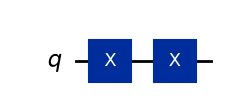

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(1.0)}

Puerta Y aplicada dos veces


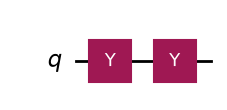

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(1.0)}

Puerta Z aplicada dos veces


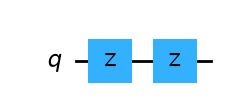

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(1.0)}

Puerta H aplicada dos veces


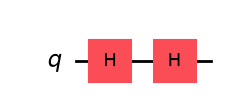

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.9999999999999996)}



In [24]:
puertas_dos_veces = ["x", "y", "z", "h"]

for nombre in puertas_dos_veces:
    qc = QuantumCircuit(1)

    getattr(qc, nombre)(0)
    getattr(qc, nombre)(0)

    print(f"Puerta {nombre.upper()} aplicada dos veces")
    estado, probs = analizar_circuito(qc)
    print()

Completa la tabla:

| Puerta aplicada dos veces | Estado final |
|---|---|
| X | $\|0\rangle$ |
| Y | $\|0\rangle$ |
| Z | $\|0\rangle$ |
| H | $\|0\rangle$ |

**Responde:**

1. ¿Qué tienen en común estas puertas?
    - Son unitarias y hermíticas.
2. ¿Qué significa que una puerta sea su propia inversa? 
    - Que si se aplica dos veces devuelve el estado inicial.
3. ¿Se cumple exactamente o aparece alguna fase global en algún caso?
    - Se cumple exactamente.

### Ejercicio 18. Inversas de S y T

Crea los siguientes circuitos:

```python
qc_s = QuantumCircuit(1)
qc_s.h(0)
qc_s.s(0)
qc_s.sdg(0)
```

```python
qc_t = QuantumCircuit(1)
qc_t.h(0)
qc_t.t(0)
qc_t.tdg(0)
```

S seguida de Sdg


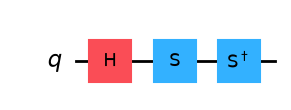

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
T seguida de Tdg


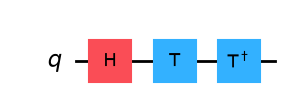

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999998)}


In [25]:
qc_s_inv = QuantumCircuit(1)
qc_s_inv.h(0)
qc_s_inv.s(0)
qc_s_inv.sdg(0)

qc_t_inv = QuantumCircuit(1)
qc_t_inv.h(0)
qc_t_inv.t(0)
qc_t_inv.tdg(0)

print("S seguida de Sdg")
estado_s_inv, probs_s_inv = analizar_circuito(qc_s_inv)

print("T seguida de Tdg")
estado_t_inv, probs_t_inv = analizar_circuito(qc_t_inv)

**Responde:**

1. ¿Qué hace `sdg`?
    - Es la inversa de $S$
2. ¿Qué hace `tdg`?
    - Es la inversa de $T$
3. ¿Por qué el estado final vuelve a coincidir con el estado anterior a aplicar `s` o `t`?
    - Porque se cancelan. $S\dagger S=I$ y $T\dagger T=I$.
4. ¿Qué relación tiene esto con la reversibilidad?
    - Que las puertas cuanticas son reversibles, siempre hay otra puerta que deshace la primera

## 9. Parte H. Rotaciones

### Ejercicio 19. Rotación $R_y(\theta)$

Crea circuitos que apliquen $R_y(\theta)$ sobre $|0\rangle$ para los siguientes valores:

$$
\theta = 0,\ \frac{\pi}{4},\ \frac{\pi}{2},\ \pi
$$

theta = 0


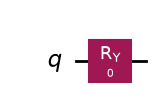

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(1.0)}

theta = 0.7853981633974483


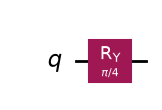

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.8535533905932737), np.str_('1'): np.float64(0.14644660940672624)}

theta = 1.5707963267948966


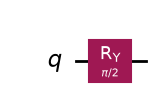

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.5000000000000001), np.str_('1'): np.float64(0.5000000000000001)}

theta = 3.141592653589793


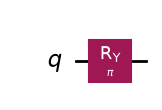

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(3.749399456654644e-33), np.str_('1'): np.float64(1.0)}



In [26]:
angulos = [0, np.pi / 4, np.pi / 2, np.pi]
resultados_ry = []

for theta in angulos:
    qc = QuantumCircuit(1)

    qc.ry(theta, 0)

    estado = Statevector.from_instruction(qc)
    probs = estado.probabilities_dict()

    resultados_ry.append((theta, estado, probs))

    print("theta =", theta)
    display(qc.draw("mpl"))
    display(estado.draw("latex"))
    print(probs)
    print()

Completa la tabla:

| $\theta$ | Estado aproximado | P(0) | P(1) |
|---:|---|---:|---:|
| 0 | $\|0\rangle$ | 1 | 0 |
| $\pi/4$ | $0{,}924\|0\rangle+0{,}383\|1\rangle$ | 0,854 | 0,146 |
| $\pi/2$ | $(\|0\rangle+\|1\rangle)/\sqrt{2}$ | 0,5 | 0,5 |
| $\pi$ | $\|1\rangle$ | 0 | 1 |

**Responde:**

1. ¿Qué ocurre cuando aumenta $\theta$?
    - P(1) va aumentando y P(0) disminuye, hasta que $\theta =0$ y solo queda $\ket1$
2. ¿Qué valor de $\theta$ produce una superposición equilibrada?
    - $\theta=\pi/2$
3. ¿Qué valor de $\theta$ lleva aproximadamente de $|0\rangle$ a $|1\rangle$?
    - $\theta=\pi$
4. ¿Por qué las rotaciones son útiles?
    - Porque permiten preparar estados con probabilidades que se pueden ajustar con el angulo.

### Ejercicio 20. Rotación $R_z(\theta)$)

Crea circuitos que preparen primero $|+\rangle$ y después apliquen $R_z(\theta)$:

```python
qc = QuantumCircuit(1)
qc.h(0)
qc.rz(theta, 0)
```

Utiliza:

$$
\theta = 0,\ \frac{\pi}{2},\ \pi
$$

theta = 0


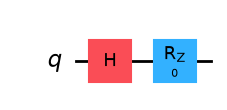

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}

theta = 1.5707963267948966


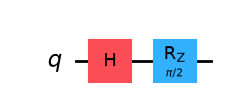

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.5000000000000001), np.str_('1'): np.float64(0.5000000000000001)}

theta = 3.141592653589793


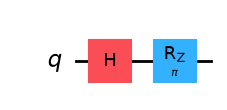

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}



In [27]:
angulos_rz = [0, np.pi / 2, np.pi]
resultados_rz = []

for theta in angulos_rz:
    qc = QuantumCircuit(1)

    qc.h(0)
    qc.rz(theta, 0)

    estado = Statevector.from_instruction(qc)
    probs = estado.probabilities_dict()

    resultados_rz.append((theta, estado, probs))

    print("theta =", theta)
    display(qc.draw("mpl"))
    display(estado.draw("latex"))
    print(probs)
    print()

**Responde:**

1. ¿Cambian las probabilidades?
    - No.
2. ¿Cambia el estado?
    - Sí, cambia cuando $\theta \neq 0$
3. ¿Qué modifica principalmente $R_z$?
    - La fase relativa entre $\ket0$ y $\ket1$
4. ¿Por qué este efecto puede no verse en un histograma de la base computacional?
    - Porque solo depende del modulo de las amplitudes y no de las fases

## 10. Parte I. Medidas y conteos

### Ejercicio 21. Medir después de aplicar puertas

Crea un circuito que prepare el estado:

$$
|+\rangle =
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

y lo mida con `shots = 1000`.

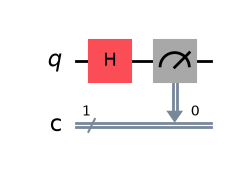

{'0': 514, '1': 486}

In [28]:
shots = 1000

qc_medida = QuantumCircuit(1, 1)

qc_medida.h(0)
qc_medida.measure(0, 0)

display(qc_medida.draw("mpl"))

simulador = AerSimulator(seed_simulator=SEMILLA)
qc_t = transpile(qc_medida, simulador)

resultado = simulador.run(qc_t, shots=shots).result()
conteos = resultado.get_counts()

conteos

**Responde:**

1. ¿Qué resultados esperas obtener?
    - 0 = 0,5 y 1 = 0,5
2. ¿Coinciden exactamente con 500 y 500?
    - No, se acercan.
3. ¿Por qué?
    - Porque es una estimación. Cada shot es aleatorio y hay un numero finito de shots.
4. ¿Qué diferencia hay entre probabilidades teóricas y conteos?
    - Las probabilidades teóricas son exactas y los conteos son una estimacion estadistica.

### Ejercicio 22. Histograma de resultados

Representa los conteos del ejercicio anterior mediante un gráfico de barras.

El gráfico debe incluir:

- Título.
- Etiqueta del eje X.
- Etiqueta del eje Y.
- Valores encima de las barras.

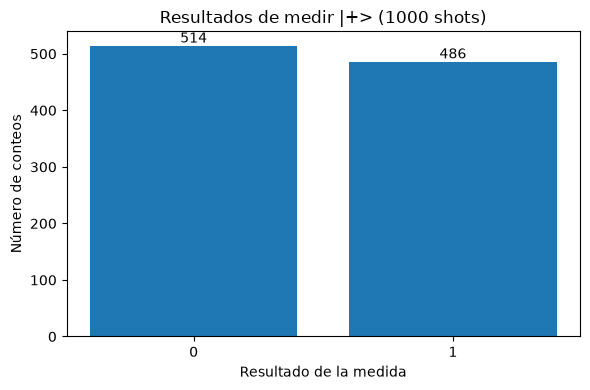

In [29]:
etiquetas = sorted(conteos.keys())
valores = [conteos[k] for k in etiquetas]

fig, ax = plt.subplots(figsize=(6, 4))

barras = ax.bar(etiquetas, valores)

ax.set_title("Resultados de medir |+> (1000 shots)")
ax.set_xlabel("Resultado de la medida")
ax.set_ylabel("Número de conteos")
for barra, valor in zip(barras, valores):
    ax.text(barra.get_x() + barra.get_width() / 2, valor, str(valor), ha="center", va="bottom")

plt.tight_layout()
plt.show()

**Responde:**

1. ¿Qué representa el histograma?
    - Cuantas veces ha salido cada resultado (0,1) en los 1000 shots
2. ¿Muestra directamente las amplitudes?
    - No, los conteos.
3. ¿Muestra directamente la fase?
    - No, no se ve la fase.
4. ¿Qué información se pierde al medir?
    - La fase y las amplitudes.

## 11. Reto avanzado

### Ejercicio 23. Distinguir $|+\rangle$ y $|-\rangle$ mediante una operación previa

Sabemos que $|+\rangle$ y $|-\rangle$ producen las mismas probabilidades si se miden directamente en la base computacional.

Diseña un procedimiento con Qiskit para distinguirlos.

Pista: antes de medir, aplica una puerta adecuada.

Debes construir dos circuitos:

1. Uno que prepare $|+\rangle$, aplique la operación elegida y mida.
2. Otro que prepare $|-\rangle$, aplique la operación elegida y mida.

Ejecuta ambos con `shots=1000`.

In [30]:
qc_plus_medida = QuantumCircuit(1, 1)
qc_plus_medida.h(0)        # prepara |+>
qc_plus_medida.h(0)        # operación previa a la medida
qc_plus_medida.measure(0, 0)

qc_minus_medida = QuantumCircuit(1, 1)
qc_minus_medida.h(0)
qc_minus_medida.z(0)       # prepara |->
qc_minus_medida.h(0)       # operación previa a la medida
qc_minus_medida.measure(0, 0)

simulador = AerSimulator(seed_simulator=SEMILLA)

qc_plus_t = transpile(qc_plus_medida, simulador)
qc_minus_t = transpile(qc_minus_medida, simulador)

conteos_plus = simulador.run(qc_plus_t, shots=shots).result().get_counts()
conteos_minus = simulador.run(qc_minus_t, shots=shots).result().get_counts()

print("Conteos para |+>:", conteos_plus)
print("Conteos para |->:", conteos_minus)

Conteos para |+>: {'0': 1000}
Conteos para |->: {'1': 1000}


Completa la tabla:

| Estado inicial | Operación antes de medir | Resultado esperado | Conteos obtenidos |
|---|---|---|---|
| $\|+\rangle$ | H | Siempre 0 | {'0': 1000} |
| $\|-\rangle$ | H | Siempre 1 | {'1': 1000} |

**Responde:**

1. ¿Qué puerta has utilizado antes de medir?
    - La $H$
2. ¿Por qué permite distinguir los dos estados?
    - Porque la puerta $H$ convierte la fase relativa en probabilidad: $H\ket+=\ket0$ y $H\ket-=\ket1$
3. ¿Qué resultado se obtiene para $|+\rangle$?
    - Siempre 0
4. ¿Qué resultado se obtiene para $|-\rangle$?
    - Siempre 1
5. ¿Qué demuestra este experimento sobre la fase relativa?
    - Que la fase relativa si tiene efecto fisico y se puede medir indirectamente gracias a operaciones con puertas.


## 12. Pruebas mínimas

Incluye al final del notebook las siguientes pruebas mediante `assert`.

Las pruebas deben ejecutarse sin errores cuando la práctica esté completada correctamente.

In [31]:
assert np.isclose(np.linalg.norm(ket_0), 1)
assert np.isclose(np.linalg.norm(ket_1), 1)

assert es_unitaria(I)
assert es_unitaria(X)
assert es_unitaria(Y)
assert es_unitaria(Z)
assert es_unitaria(H)
assert es_unitaria(S)
assert es_unitaria(T)

assert np.allclose(X @ ket_0, ket_1)
assert np.allclose(H @ ket_0, ket_plus)
assert np.allclose(H @ H, I)

for estado in [ket_0, ket_1, ket_plus, ket_minus]:
    probs = probabilidades(estado)
    assert np.isclose(sum(probs.values()), 1)

assert sum(conteos.values()) == shots

## 13. Conclusión final

Redacta una conclusión de entre 150 y 250 palabras respondiendo a estas preguntas:

1. ¿Qué es una puerta cuántica de un qubit?
    - Es una operacion que transforma el estado de un qubit y se representa con una matriz 2x2.
2. ¿Por qué las puertas cuánticas deben ser unitarias?
    - Porque asi conserva la norma del vector y no cambia que las probabilidades sumen 1, además es reversible.
3. ¿Qué diferencia hay entre una puerta que cambia probabilidades y una puerta que cambia fase?
4. ¿Por qué dos estados distintos pueden producir el mismo histograma?
    - Hay puertas que cambian las probabilidades de medida, como X y H, y puertas que solo cambian la fase relativa. Estas ultimas no se notan en un histograma de la base computacional y por eso dos estados distintos pueden dar el mismo histograma. La fase solo se vuelve visible cuando se hace intergerir los estados con otra puerta, como en el ejercicio anterior, que convierte la fase en probabilidad
5. ¿Por qué el orden de las puertas importa?
    - Porque las matrices en general no conmutan, y dan estados distintos. Además de que el orden de lectura de circuitos y matrices es inverso.
6. ¿Qué has comprobado al comparar NumPy y Qiskit?  
    - Que los resultados son iguales, son dos formas de describir estados distintas pero en esencia son equivalentes